In [16]:
import numpy as np
import pandas as pd
import os
import re
import seaborn as sns
import matplotlib.pyplot as plt
import json

In [17]:
default_config = {
    "clean_interval": 100,
    "cluster_interval": 1000,
    "decay_rate": 0.005,
    "min_num_mc": 5,
    "adaptive_threshold": 1,
    "sigma": 1.0,
    "threshold_momentum": 0.0,
    "use_heuristic": 1,
    "time_gap": 1000,
    "model": "sentenceTransformers",
}

In [18]:
# Read evaluation results
files = os.listdir("smac3_results_eval_threshold15")
dfs = []
for file in files:
    if file.endswith(".json"):
        df = pd.read_csv(os.path.join("smac3_results_eval_threshold15", file))
        dfs.append(df)
        
eval_df = pd.concat(dfs, ignore_index=True)
eval_df.head()

eval_df["dataset"] = eval_df["dataset"].str.replace("examples/data/", "").str.replace(".json", "")
# Replace "NTSO-T" with "NTSO" (typo in dataset names)
eval_df["dataset"] = eval_df["dataset"].str.replace("NTSO-T", "NTSO")

eval_df["is_train"] = eval_df["dataset"] != eval_df["loo_dataset"]

# Read configs

pareto_configs = []

for c in os.listdir("smac3_results_threshold15"):
    with open(f"smac3_results_threshold15/{c}", "r") as f:
        configs = json.load(f)
        for id, config in enumerate(configs):
            config["config_id"] = id
            config["config"] = c
            pareto_configs.append(config)

config_df = pd.DataFrame(pareto_configs)

# Merge with eval results
eval_df = pd.merge(eval_df, config_df, on=["config_id", "config"], how="inner")
eval_df.head()

,dataset,neg_nmi,neg_throughput,config,config_id,loo_dataset,seed,is_train,adaptive_threshold,clean_interval,cluster_interval,decay_rate,min_num_mc,model,use_heuristic,min_weight,sigma,threshold_momentum,time_gap,radius
0,Semantic10-T,-0.770550,-68.809365,best_config_loo_Trends-T_seed_4.json,0,Trends-T,4,True,1,131,2349,0.000883,17,sentenceTransformers,0,0.003965,2.687813,0.037994,NaN,NaN
1,Semantic10-T,-0.574116,-1401.232960,best_config_loo_Trends-T_seed_4.json,1,Trends-T,4,True,1,386,3468,0.002085,16,minishlab,1,NaN,1.555361,0.562314,3048.503859,NaN
2,Semantic10-T,-0.658934,-1126.828243,best_config_loo_Trends-T_seed_4.json,2,Trends-T,4,True,1,283,1925,0.001290,19,minishlab,1,NaN,2.632982,0.153899,1186.367918,NaN
3,Semantic10-T,-0.694323,-1048.154132,best_config_loo_Trends-T_seed_4.json,3,Trends-T,4,True,1,490,1907,0.001090,18,minishlab,1,NaN,2.881993,0.156900,1035.853494,NaN
4,Semantic10-T,-0.742763,-884.871232,best_config_loo_Trends-T_seed_4.json,4,Trends-T,4,True,1,483,421,0.006510,26,minishlab,0,0.000012,2.843170,0.536362,NaN,NaN


In [19]:
from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Any

import pandas as pd


_LOO_FOLDER_RE = re.compile(r"loo_(?P<loo_dataset>.+?)_seed_(?P<seed>[^/\\]+)")
_THROUGHPUT_RE = re.compile(r"Throughput\s+(?P<throughput>[0-9]*\.?[0-9]+)")


def _extract_metadata_from_path(path: Path) -> tuple[str | None, int | str | None]:
    for part in path.parts:
        match = _LOO_FOLDER_RE.fullmatch(part)
        if match:
            seed = match.group("seed")
            return match.group("loo_dataset"), int(seed) if seed.isdigit() else seed

    return None, None


def _extract_theoretical_throughput(additional_info: Any) -> float | None:
    if not isinstance(additional_info, dict):
        return None

    for key in ("error", "traceback"):
        value = additional_info.get(key)
        if not isinstance(value, str):
            continue

        match = _THROUGHPUT_RE.search(value)
        if match:
            return float(match.group("throughput"))

    return np.nan


def _flatten_configuration(configuration: Any) -> dict[str, Any]:
    if isinstance(configuration, dict):
        return dict(configuration)
    return {}


def _expand_costs(costs: Any) -> dict[str, Any]:
    if isinstance(costs, list):
        return {f"cost_{index + 1}": cost for index, cost in enumerate(costs)}
    if costs is None:
        return {}
    return {"cost_1": costs}


def runhistory_to_dataframe(runhistory_path: str | Path) -> pd.DataFrame:
    """Read one SMAC runhistory file into a flat dataframe.

    Each configuration option becomes its own column and each cost becomes its own column.
    """

    runhistory_path = Path(runhistory_path)
    loo_dataset, seed = _extract_metadata_from_path(runhistory_path)

    with runhistory_path.open() as file_handle:
        runhistory = json.load(file_handle)

    configs = runhistory.get("configs", {})
    rows: list[dict[str, Any]] = []

    for i, run in enumerate(runhistory.get("data", [])):
        config_id = run.get("config_id")
        config_key = str(config_id)
        configuration = configs.get(config_key, configs.get(config_id, {}))

        row = {
            "config_path": str(runhistory_path),
            "config_id": config_id,
            "run_index": i,
            "instance": run.get("instance"),
            "seed": seed,
            "loo_dataset": loo_dataset,
            "theoretical_throughput": _extract_theoretical_throughput(run.get("additional_info")),
        }
        row.update(_flatten_configuration(configuration))
        row.update(_expand_costs(run.get("cost")))
        rows.append(row)

    return pd.DataFrame(rows)


def runhistory_folder_to_dataframe(root_folder: str | Path) -> pd.DataFrame:
    """Read all runhistory files below a SMAC output root into one dataframe."""

    root_folder = Path(root_folder)
    runhistory_files = sorted(root_folder.rglob("runhistory.json"))

    if not runhistory_files:
        return pd.DataFrame(
            columns=["config_id", "instance", "seed", "loo_dataset", "theoretical_throughput", "run_index", "config_path"]
        )

    frames = [runhistory_to_dataframe(runhistory_file) for runhistory_file in runhistory_files]
    return pd.concat(frames, ignore_index=True)

runhistory_df = runhistory_folder_to_dataframe("smac3_output_threshold15")
runhistory_df = runhistory_df.rename(columns={"cost_1": "neg_nmi", "cost_2": "neg_throughput"})
runhistory_df["instance"] = runhistory_df["instance"].str.replace("examples/data/", "").str.replace(".json", "")
runhistory_df["instance"] = runhistory_df["instance"].str.replace("NTSO-T", "NTSO")

runhistory_df.head()

,config_path,config_id,run_index,instance,seed,loo_dataset,theoretical_throughput,adaptive_threshold,clean_interval,cluster_interval,...,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,neg_nmi,neg_throughput,min_weight,radius
0,smac3_output_threshold15/loo_NTSO_seed_0/47274...,1,0,Trends-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.584989,-43.589021,NaN,NaN
1,smac3_output_threshold15/loo_NTSO_seed_0/47274...,1,1,Semantic40-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.359229,-58.589278,NaN,NaN
2,smac3_output_threshold15/loo_NTSO_seed_0/47274...,2,2,Semantic40-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.476544,-58.332251,0.01,NaN
3,smac3_output_threshold15/loo_NTSO_seed_0/47274...,2,3,Trends-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.510824,-41.190361,0.01,NaN
4,smac3_output_threshold15/loo_NTSO_seed_0/47274...,1,4,News-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.193916,-53.977370,NaN,NaN


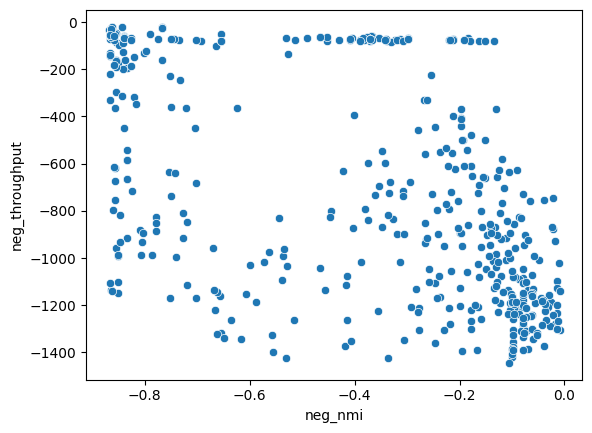

In [20]:
df = eval_df.copy()
df = df[(df["dataset"] == "NTSO") & (df["is_train"] == True)]

scatter = sns.scatterplot(df, x="neg_nmi", y="neg_throughput")

(-1.0, 0.0)

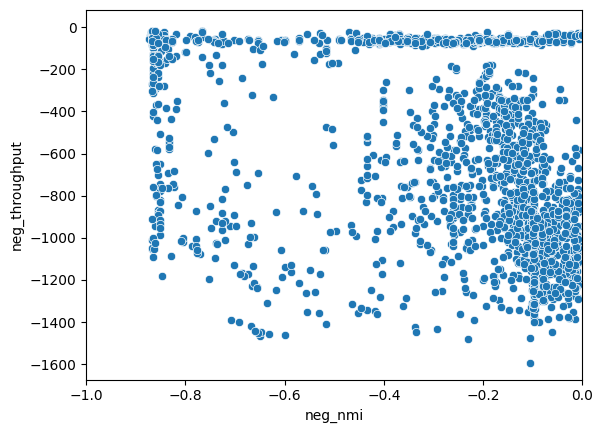

In [21]:
df = runhistory_df.copy()
df = df[df["instance"] == "NTSO"]

sns.scatterplot(df, x="neg_nmi", y="neg_throughput")

plt.xlim(-1.0, 0)

In [22]:
runhistory_df.head()

,config_path,config_id,run_index,instance,seed,loo_dataset,theoretical_throughput,adaptive_threshold,clean_interval,cluster_interval,...,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,neg_nmi,neg_throughput,min_weight,radius
0,smac3_output_threshold15/loo_NTSO_seed_0/47274...,1,0,Trends-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.584989,-43.589021,NaN,NaN
1,smac3_output_threshold15/loo_NTSO_seed_0/47274...,1,1,Semantic40-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.359229,-58.589278,NaN,NaN
2,smac3_output_threshold15/loo_NTSO_seed_0/47274...,2,2,Semantic40-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.476544,-58.332251,0.01,NaN
3,smac3_output_threshold15/loo_NTSO_seed_0/47274...,2,3,Trends-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.510824,-41.190361,0.01,NaN
4,smac3_output_threshold15/loo_NTSO_seed_0/47274...,1,4,News-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.193916,-53.977370,NaN,NaN


(-1.0, 0.0)

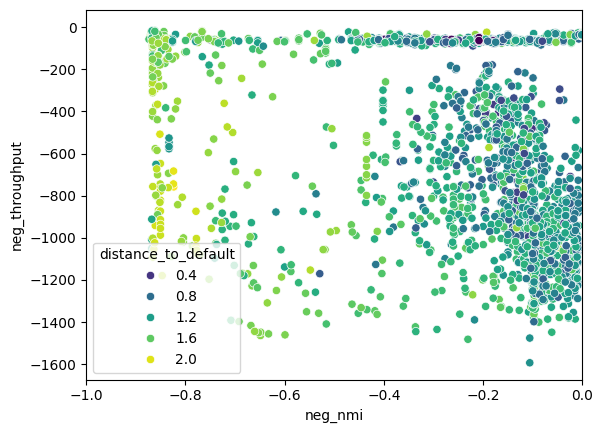

In [34]:
df = runhistory_df.copy()
df = df[df["instance"] == "NTSO"]
model_ranking = {
    "minishlab" : 1,
    "sentenceTransformers" : 2,
    "maniac" : 3,
    "clips" : 4,
}
df["model"] = df["model"].map(model_ranking)

cols_to_normalize = [
   "model",
   "clean_interval",
   "cluster_interval",
   "decay_rate",
   "min_num_mc",
   "adaptive_threshold",
   "use_heuristic"
]

#Min-Max normalization for all columns except first 4 columns
mins = df[cols_to_normalize].min()
maxs = df[cols_to_normalize].max()
df[cols_to_normalize] = (df[cols_to_normalize] - mins) / (maxs - mins)

default_config_normalized = default_config.copy()
default_config_normalized["model"] = model_ranking[default_config["model"]]
for key in default_config_normalized:
    if key in mins and key in maxs:
        default_config_normalized[key] = (default_config_normalized[key] - mins[key]) / (maxs[key] - mins[key])
        
configs = df[cols_to_normalize].to_numpy()
comparable_default_config = [default_config_normalized[key] for key in cols_to_normalize]
        
df["distance_to_default"] = np.sqrt(np.sum((configs - comparable_default_config) ** 2, axis=1))
sns.scatterplot(df, x="neg_nmi", y="neg_throughput", hue="distance_to_default", palette="viridis")
plt.xlim(-1.0, 0)

In [35]:
import numpy as np
from typing import Sequence


def pareto_front_2d(points: np.ndarray) -> np.ndarray:
    """
    Extract the Pareto-optimal front from a set of 2D points (minimization).

    A point is Pareto-optimal if no other point dominates it, i.e. no other
    point is at least as good in both objectives and strictly better in one.

    Args:
        points: Array of shape (n, 2) with objective values.

    Returns:
        Array of shape (m, 2) containing only the non-dominated points,
        sorted by the first objective in ascending order.
    """
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError("points must have shape (n, 2)")

    # Sort by first objective ascending, break ties by second objective ascending
    order = np.lexsort((points[:, 1], points[:, 0]))
    sorted_pts = points[order]

    pareto = [sorted_pts[0]]
    min_obj2 = sorted_pts[0, 1]

    for pt in sorted_pts[1:]:
        # A new point is non-dominated iff its second objective is strictly
        # better than the best second-objective seen so far among points with
        # a smaller (or equal) first objective.
        if pt[1] < min_obj2:
            pareto.append(pt)
            min_obj2 = pt[1]

    return np.array(pareto)


def hypervolume_2d(
    points: Sequence,
    reference_point: Sequence,
) -> float:
    """
    Compute the hypervolume indicator for a 2-objective minimization problem.

    The hypervolume is the area of the objective space that is dominated by
    the Pareto front and bounded by the reference point.  The function
    automatically filters the supplied points to their Pareto front before
    computing, so you can pass the full population without pre-filtering.

    Args:
        points:          Sequence of (f1, f2) objective pairs.  May contain
                         dominated points – they are ignored automatically.
        reference_point: A point (r1, r2) that is dominated by every point on
                         the Pareto front (i.e. r1 >= max f1, r2 >= max f2).

    Returns:
        The hypervolume as a non-negative float.

    Raises:
        ValueError: If points is empty, has wrong shape, or the reference
                    point does not dominate every Pareto-front point.

    Example:
        >>> pts = [(1, 4), (2, 3), (3, 1), (2.5, 2), (3, 3)]  # (3,3) dominated
        >>> hypervolume_2d(pts, reference_point=(4, 5))
        8.0
    """
    pts = np.asarray(points, dtype=float)
    if pts.ndim != 2 or pts.shape[1] != 2:
        raise ValueError("points must be an (n, 2) array-like")

    ref = np.asarray(reference_point, dtype=float)
    if ref.shape != (2,):
        raise ValueError("reference_point must be a sequence of length 2")

    # --- 1. Extract Pareto front -----------------------------------------
    front = pareto_front_2d(pts)  # sorted by f1 ascending, f2 descending

    # --- 2. Validate reference point -------------------------------------
    if np.any(ref <= front.min(axis=0)):
        raise ValueError(
            "reference_point must be strictly greater than the minimum of "
            "each objective across the Pareto front."
        )

    # --- 3. Sweep-line integration ----------------------------------------
    # The front is already sorted by f1 ascending (and f2 descending, because
    # it is a Pareto front).  Walk left-to-right and accumulate rectangles:
    #
    #   width  = f1[i+1] - f1[i]   (or ref[0] - f1[last] for the final strip)
    #   height = ref[1]  - f2[i]
    #
    #   ref[1]  ┤─────────────────────────────┐
    #           │        │        │            │
    #    f2[0]  │--------*        │            │
    #           │ rect0  │        │            │
    #    f2[1]  │        *--------│            │
    #           │        │ rect1  │            │
    #    f2[2]  │        │        *────────────┤ ← last strip reaches ref[0]
    #           └────────┴────────┴────────────┘
    #          f1[0]   f1[1]   f1[2]        ref[0]

    hv = 0.0
    n = len(front)
    for i in range(n):
        width = (front[i + 1, 0] if i + 1 < n else ref[0]) - front[i, 0]
        height = ref[1] - front[i, 1]
        hv += width * height

    return float(hv)


# ---------------------------------------------------------------------------
# Quick smoke-test
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    # Pareto front: (1,4), (2,3), (3,1)  –  dominated: (2.5,2) no wait…
    # Let's trace manually with reference (4,5):
    #   Strip 0: width=2-1=1,  height=5-4=1  → 1
    #   Strip 1: width=3-2=1,  height=5-3=2  → 2
    #   Strip 2: width=4-3=1,  height=5-1=4  → 4  (last strip, ref[0]=4)
    #   Total = 7  ← note (2.5,2) is dominated by (2,3) so it is excluded

    population = [(1, 4), (2, 3), (3, 1), (2.5, 2), (3, 3)]
    ref = (4, 5)

    front = pareto_front_2d(np.array(population))
    hv = hypervolume_2d(population, ref)

    print("Population :", population)
    print("Pareto front:\n", front)
    print(f"Hypervolume (ref={ref}): {hv}")   # expected: 7.0

Population : [(1, 4), (2, 3), (3, 1), (2.5, 2), (3, 3)]
Pareto front:
 [[1.  4. ]
 [2.  3. ]
 [2.5 2. ]
 [3.  1. ]]
Hypervolume (ref=(4, 5)): 7.5


In [ ]:
import shap

def value_func(X):
    # Compute the hypervolume for each configuration in X
    hv_values = []
    for config in X:
        # Assuming config is a 1D array with the necessary parameters
        # You would need to convert this config into the appropriate format
        # to compute the hypervolume. This is a placeholder.
        hv = hypervolume_2d(config, reference_point=(4, 5))  # Example reference point
        hv_values.append(hv)
    return np.array(hv_values)

